In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv(r"C:\Users\HP\auspify-ml-internship\data\netflix_clean.csv")

counts = df["rating"].value_counts()
print(pd.DataFrame({"count": counts, "share": (counts / len(df)).round(3)}))

print(pd.crosstab(df["rating"], df["type"]))

          count  share
rating                
TV-MA      3205  0.365
TV-14      2157  0.245
TV-PG       861  0.098
R           799  0.091
PG-13       490  0.056
TV-Y7       333  0.038
TV-Y        306  0.035
PG          287  0.033
TV-G        220  0.025
NR           79  0.009
G            41  0.005
TV-Y7-FV      6  0.001
NC-17         3  0.000
UR            3  0.000
type      Movie  TV Show
rating                  
G            41        0
NC-17         3        0
NR           75        4
PG          287        0
PG-13       490        0
R           797        2
TV-14      1427      730
TV-G        126       94
TV-MA      2062     1143
TV-PG       540      321
TV-Y        131      175
TV-Y7       139      194
TV-Y7-FV      5        1
UR            3        0


In [2]:
mapping = {
    "TV-Y": "Kids", "TV-Y7": "Kids", "TV-Y7-FV": "Kids", "TV-G": "Kids", "G": "Kids",
    "TV-PG": "Family", "PG": "Family",
    "TV-14": "Teens", "PG-13": "Teens",
    "TV-MA": "Adults", "R": "Adults", "NC-17": "Adults",
}

df["audience"] = df["rating"].map(mapping)
print("dropped (NR, UR):", df["audience"].isna().sum())

df = df.dropna(subset=["audience"]).reset_index(drop=True)
print(df.shape)

dist = df["audience"].value_counts()
print(pd.DataFrame({"count": dist, "share": (dist / len(df)).round(3)}))

dropped (NR, UR): 82
(8708, 15)
          count  share
audience              
Adults     4007  0.460
Teens      2647  0.304
Family     1148  0.132
Kids        906  0.104


In [3]:
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.model_selection import train_test_split

# duration split + director flag
df["movie_minutes"] = np.where(df["type"] == "Movie", df["duration_value"], 0)
df["tv_seasons"] = np.where(df["type"] == "TV Show", df["duration_value"], 0)
df["director_known"] = (df["director"] != "Unknown").astype(int)

# one 0/1 column per genre
mlb = MultiLabelBinarizer()
G = pd.DataFrame(
    mlb.fit_transform(df["listed_in"].str.split(", ")),
    columns=["g_" + c for c in mlb.classes_],
    index=df.index,
)
df = pd.concat([df, G], axis=1)
genre_cols = list(G.columns)

num_cols = ["release_year", "year_added", "movie_minutes", "tv_seasons"]
cat_cols = ["type", "country"]
features = num_cols + cat_cols + ["director_known"] + genre_cols

X = df[features]
y = df["audience"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# country: top 10 + Other, from the training set only
top_countries = X_train["country"].value_counts().head(10).index
X_train = X_train.copy()
X_test = X_test.copy()
X_train["country"] = X_train["country"].where(X_train["country"].isin(top_countries), "Other")
X_test["country"] = X_test["country"].where(X_test["country"].isin(top_countries), "Other")

print(X_train.shape, X_test.shape)
print(len(genre_cols), "genre columns")
print(y_train.value_counts(normalize=True).round(3))
print(y_test.value_counts(normalize=True).round(3))

(6966, 49) (1742, 49)
42 genre columns
audience
Adults    0.460
Teens     0.304
Family    0.132
Kids      0.104
Name: proportion, dtype: float64
audience
Adults    0.460
Teens     0.304
Family    0.132
Kids      0.104
Name: proportion, dtype: float64


In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

flag_cols = ["director_known"] + genre_cols

pre = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("flags", "passthrough", flag_cols),
])

models = {
    "Baseline (always Adults)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
}

results = []
for name, model in models.items():
    pipe = Pipeline([("pre", pre), ("clf", model)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    results.append({
        "model": name,
        "accuracy": accuracy_score(y_test, pred),
        "macro_f1": f1_score(y_test, pred, average="macro"),
    })

pd.DataFrame(results).round(3)

,model,accuracy,macro_f1
0,Baseline (always Adults),0.460,0.158
1,Logistic Regression,0.626,0.587
2,Decision Tree,0.564,0.539
3,Random Forest,0.626,0.598


In [5]:
from sklearn.metrics import classification_report, confusion_matrix

rf = Pipeline([("pre", pre), ("clf", RandomForestClassifier(random_state=42))])
rf.fit(X_train, y_train)
pred = rf.predict(X_test)

labels = ["Kids", "Family", "Teens", "Adults"]
print(classification_report(y_test, pred, labels=labels))
print(pd.DataFrame(
    confusion_matrix(y_test, pred, labels=labels),
    index=[f"true {l}" for l in labels],
    columns=[f"pred {l}" for l in labels],
))

              precision    recall  f1-score   support

        Kids       0.78      0.72      0.75       181
      Family       0.49      0.35      0.41       230
       Teens       0.53      0.49      0.51       529
      Adults       0.67      0.77      0.72       802

    accuracy                           0.63      1742
   macro avg       0.62      0.58      0.60      1742
weighted avg       0.62      0.63      0.62      1742

             pred Kids  pred Family  pred Teens  pred Adults
true Kids          131           21          14           15
true Family         28           81          63           58
true Teens           6           35         259          229
true Adults          2           28         152          620


In [6]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

pipe = Pipeline([("pre", pre), ("clf", RandomForestClassifier(random_state=42, n_jobs=-1))])

param_grid = {
    "clf__n_estimators": [300],
    "clf__max_depth": [10, 20, None],
    "clf__min_samples_leaf": [1, 3, 5],
    "clf__class_weight": [None, "balanced"],
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid = GridSearchCV(pipe, param_grid, cv=cv, scoring="f1_macro", n_jobs=-1, verbose=1)
grid.fit(X_train, y_train)

print("best params:", grid.best_params_)
print("best CV macro F1:", round(grid.best_score_, 3))

cv_table = pd.DataFrame(grid.cv_results_)[
    ["param_clf__max_depth", "param_clf__min_samples_leaf", "param_clf__class_weight", "mean_test_score"]
].sort_values("mean_test_score", ascending=False)
print(cv_table.head(8).round(3))

Fitting 5 folds for each of 18 candidates, totalling 90 fits
best params: {'clf__class_weight': 'balanced', 'clf__max_depth': 20, 'clf__min_samples_leaf': 3, 'clf__n_estimators': 300}
best CV macro F1: 0.635
   param_clf__max_depth  param_clf__min_samples_leaf param_clf__class_weight  \
13                   20                            3                balanced   
16                 None                            3                balanced   
17                 None                            5                balanced   
14                   20                            5                balanced   
9                    10                            1                balanced   
10                   10                            3                balanced   
11                   10                            5                balanced   
12                   20                            1                balanced   

    mean_test_score  
13            0.635  
16            0.634  
17   

In [7]:
from sklearn.model_selection import cross_val_score
from sklearn.metrics import classification_report, confusion_matrix

best = grid.best_estimator_

# untuned Random Forest on the same CV folds
untuned = Pipeline([("pre", pre), ("clf", RandomForestClassifier(random_state=42, n_jobs=-1))])
cv_untuned = cross_val_score(untuned, X_train, y_train, cv=cv, scoring="f1_macro")
print("CV macro F1 | untuned:", cv_untuned.mean().round(3), "| tuned:", round(grid.best_score_, 3))

# test set, both models
untuned.fit(X_train, y_train)
for name, m in [("untuned", untuned), ("tuned", best)]:
    p = m.predict(X_test)
    print(f"{name}: accuracy {accuracy_score(y_test, p):.3f} | macro F1 {f1_score(y_test, p, average='macro'):.3f}")

# per-class report for the tuned model
pred = best.predict(X_test)
labels = ["Kids", "Family", "Teens", "Adults"]
print(classification_report(y_test, pred, labels=labels))
print(pd.DataFrame(
    confusion_matrix(y_test, pred, labels=labels),
    index=[f"true {l}" for l in labels],
    columns=[f"pred {l}" for l in labels],
))

CV macro F1 | untuned: 0.604 | tuned: 0.635
untuned: accuracy 0.626 | macro F1 0.598
tuned: accuracy 0.627 | macro F1 0.618
              precision    recall  f1-score   support

        Kids       0.82      0.74      0.78       181
      Family       0.43      0.47      0.45       230
       Teens       0.53      0.54      0.54       529
      Adults       0.72      0.70      0.71       802

    accuracy                           0.63      1742
   macro avg       0.62      0.61      0.62      1742
weighted avg       0.63      0.63      0.63      1742

             pred Kids  pred Family  pred Teens  pred Adults
true Kids          134           30          10            7
true Family         27          109          57           37
true Teens           0           64         285          180
true Adults          3           51         184          564


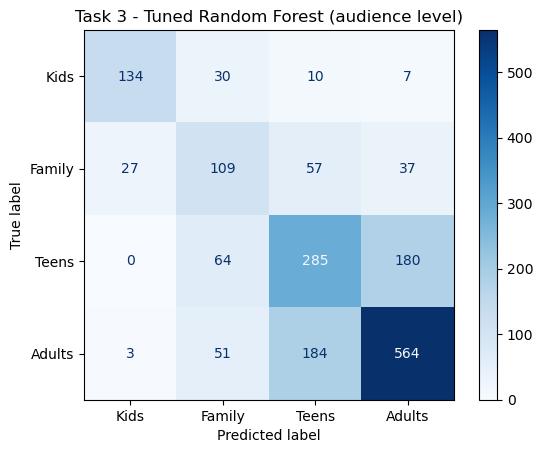

flags__g_Kids' TV                    0.148
num__movie_minutes                   0.136
flags__g_Children & Family Movies    0.130
num__release_year                    0.075
num__year_added                      0.044
flags__g_International TV Shows      0.033
flags__g_International Movies        0.027
flags__g_Dramas                      0.022
num__tv_seasons                      0.020
flags__g_Stand-Up Comedy             0.020
dtype: float64


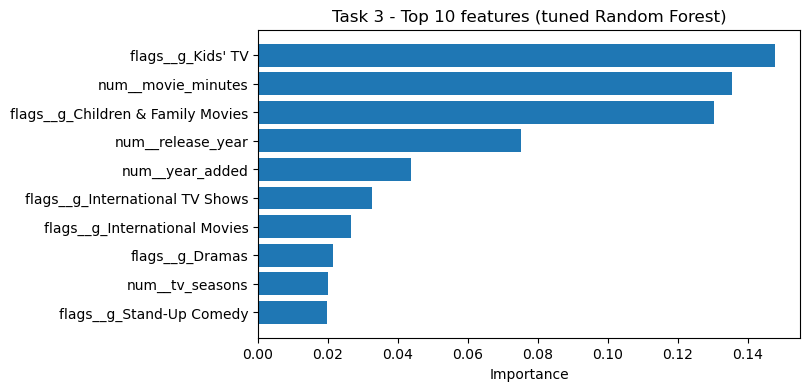

In [8]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# confusion matrix figure
ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=labels, cmap="Blues")
plt.title("Task 3 - Tuned Random Forest (audience level)")
plt.savefig("../outputs/task3_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

# top 10 feature importances
names = best.named_steps["pre"].get_feature_names_out()
imp = pd.Series(best.named_steps["clf"].feature_importances_, index=names).sort_values(ascending=False)
print(imp.head(10).round(3))

top = imp.head(10)[::-1]
plt.figure(figsize=(7, 4))
plt.barh(top.index, top.values, color="#1f77b4")
plt.xlabel("Importance")
plt.title("Task 3 - Top 10 features (tuned Random Forest)")
plt.savefig("../outputs/task3_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
## Summary: Task 3, Netflix Audience Rating Classification

**Target.** The original `rating` has 14 values, some with very few examples (`UR` 3, `NC-17` 3, `TV-Y7-FV` 6). I merged them into 4 audience levels: Kids (TV-Y, TV-Y7, TV-Y7-FV, TV-G, G), Family (TV-PG, PG), Teens (TV-14, PG-13) and Adults (TV-MA, R, NC-17). The 82 unrated titles (NR, UR) were dropped. Class shares: Adults 46%, Teens 30%, Family 13%, Kids 10%.

**Features.** Numeric (scaled): release year, year added, movie minutes, TV seasons. Categorical (one-hot): type and country (top 10 + "Other", computed on the training set only). Flags: director known and one 0/1 column per genre (42). `duration` and `listed_in` are safe to use here, because they only leaked in Task 2, where the target was `type`.

**Method.** Stratified 80/20 split, preprocessing inside a Pipeline, and macro F1 as the main metric because the classes are imbalanced. Models compared: baseline, Logistic Regression, Decision Tree, Random Forest. The Random Forest was tuned with GridSearchCV (5-fold CV, 18 combinations).

**Results (test set).**

| Model | Accuracy | Macro F1 |
|---|---|---|
| Baseline (always Adults) | 0.460 | 0.158 |
| Logistic Regression | 0.626 | 0.587 |
| Decision Tree | 0.564 | 0.539 |
| Random Forest | 0.626 | 0.598 |
| Random Forest (tuned) | 0.627 | **0.618** |

Best parameters: `class_weight="balanced"`, `max_depth=20`, `min_samples_leaf=3`, `n_estimators=300`. Tuning barely changed accuracy but improved macro F1 and the weakest class: Family recall rose from 0.35 to 0.47, at the cost of some Adults recall (0.77 to 0.70).

**Findings.**
- Kids is the best-recognized class (F1 0.78), driven by the `Kids' TV` and `Children & Family Movies` genres.
- The main confusion is Teens vs Adults (about 180 errors each way), because genre, country and year cannot tell TV-14 from TV-MA or PG-13 from R.
- Top features: `Kids' TV`, `movie_minutes`, `Children & Family Movies`, `release_year`, `year_added`.

**Limitations.**
- Accuracy of 0.63 against a 0.46 baseline shows that these features carry only a moderate signal for audience level.
- Merging 14 ratings into 4 levels makes the task easier and loses detail.
- The CV score (0.635) is slightly optimistic because the best of 18 settings was selected on the same folds.
- Feature importances favor numeric features with many distinct values.
- Without descriptions or cast, the model cannot see content such as violence or language, which are what actually separate Teens from Adults.